# simulation avec nouvelles entrées

In [1]:
# Import des bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.compose import ColumnTransformer
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.metrics import davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.base import clone
from matplotlib.dates import DateFormatter
from sklearn.base import clone
from matplotlib.dates import DateFormatter
import warnings

warnings.filterwarnings('ignore')

In [2]:
# Import necessary libraries
import pandas as pd

# Set display options
pd.set_option('display.max_columns', None)  # To display all columns
pd.set_option('display.max_rows', 100)  # To display 100 rows
pd.set_option('max_colwidth', 100)  # Increase column width for better display

# Load data
customers = pd.read_csv('olist_customers_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
order_payments = pd.read_csv('olist_order_payments_dataset.csv')
order_reviews = pd.read_csv('olist_order_reviews_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')

# Merge data
orders_customers = pd.merge(orders, customers, on='customer_id')
order_items_products = pd.merge(order_items, products, on='product_id')
orders_products = pd.merge(orders_customers, order_items_products, on='order_id')
orders_payments = pd.merge(orders_products, order_payments, on='order_id')
orders_reviews = pd.merge(orders_payments, order_reviews, on='order_id')

# Aggregate by customer
data = orders_reviews.groupby('customer_unique_id').agg({
    'payment_value': 'sum',
    'review_score': 'mean',
    'price': 'mean',
    'order_id': 'nunique',
    'product_id': 'count'
}).reset_index()

# Rename columns
data.rename(columns={
    'payment_value': 'total_payment_value',
    'review_score': 'average_review_score',
    'price': 'average_price',
    'order_id': 'total_orders',
    'product_id': 'total_products'
}, inplace=True)

# Convert boolean columns to integers
data['perfect_score'] = (data['average_review_score'] == 5).astype(int)
data['has_multiple_orders'] = (data['total_orders'] > 1).astype(int)

# Extract 'customer_unique_id' and 'order_purchase_timestamp'
timestamps = orders_reviews[['customer_unique_id', 'order_purchase_timestamp']]

# Join the aggregated DataFrame with the timestamps DataFrame
final_data = pd.merge(data, timestamps, on='customer_unique_id', how='inner')

# Select desired columns
final_data = final_data[['customer_unique_id', 'total_payment_value',
                         'total_products', 'perfect_score',
                         'has_multiple_orders', 'order_purchase_timestamp']]

In [3]:
# Pour afficher toutes les colonnes
pd.set_option('display.max_columns', None)

# Pour afficher toutes les lignes
pd.set_option('display.max_rows', 100)

# Pour augmenter la largeur de chaque colonne pour afficher plus de caractères
pd.set_option('max_colwidth', 100)

# Fusion des données
orders_customers = pd.merge(orders, customers, on='customer_id')
order_items_products = pd.merge(order_items, products, on='product_id')
orders_products = pd.merge(orders_customers, order_items_products, on='order_id')
orders_payments = pd.merge(orders_products, order_payments, on='order_id')
orders_reviews = pd.merge(orders_payments, order_reviews, on='order_id')

# Agrège par client
data = orders_reviews.groupby('customer_unique_id').agg({
    'payment_value': 'sum',
    'review_score': 'mean',
    'price': 'mean',
    'order_id': 'nunique',
    'product_id': 'count'
}).reset_index()

# Renomme les colonnes
data.rename(columns={
    'payment_value': 'total_payment_value',
    'review_score': 'average_review_score',
    'price': 'average_price',
    'order_id': 'total_orders',
    'product_id': 'total_products'
}, inplace=True)

# Convertit les colonnes booléennes en entiers
data['perfect_score'] = (data['average_review_score'] == 5).astype(int)
data['has_multiple_orders'] = (data['total_orders'] > 1).astype(int)

# Extrait les 'customer_unique_id' et 'order_purchase_timestamp'
timestamps = orders_reviews[['customer_unique_id', 'order_purchase_timestamp']]

 # Joins le DataFrame agrégé et le DataFrame de timestamps 'order_purchase_timestamp'
final_data = pd.merge(data, timestamps, on='customer_unique_id', how='inner')

final_data = final_data[['customer_unique_id','total_payment_value',
 'total_products',
 'perfect_score',
 'has_multiple_orders','order_purchase_timestamp']]

In [4]:
import pandas as pd

# Supposons que final_data soit votre DataFrame
# final_data = pd.read_csv('your_dataset.csv')

# Calculer le nombre et le pourcentage de valeurs manquantes par colonne
missing_values_count = final_data.isnull().sum()
missing_values_percent = (final_data.isnull().sum() / len(final_data)) * 100

# Créer un DataFrame récapitulatif
missing_values_df = pd.DataFrame({
    'Column_Name': missing_values_count.index,
    'Missing_Values_Count': missing_values_count.values,
    'Missing_Values_Percent': missing_values_percent.values
})

# Trier le DataFrame par le nombre de valeurs manquantes (optionnel)
missing_values_df = missing_values_df.sort_values(by='Missing_Values_Count', ascending=False)

# Afficher le DataFrame récapitulatif
print(missing_values_df)


                Column_Name  Missing_Values_Count  Missing_Values_Percent
0        customer_unique_id                     0                     0.0
1       total_payment_value                     0                     0.0
2            total_products                     0                     0.0
3             perfect_score                     0                     0.0
4       has_multiple_orders                     0                     0.0
5  order_purchase_timestamp                     0                     0.0


PARTIE 4 : ------------------------------ SIMULATION
Davies-Bouldin Score: 0.794831989047917


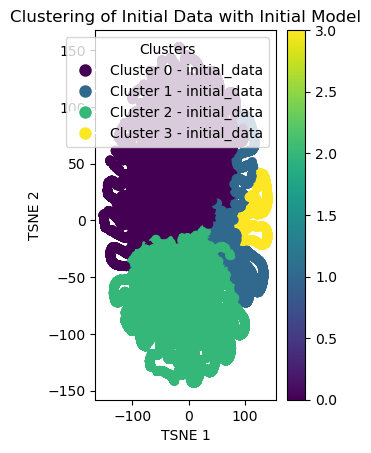

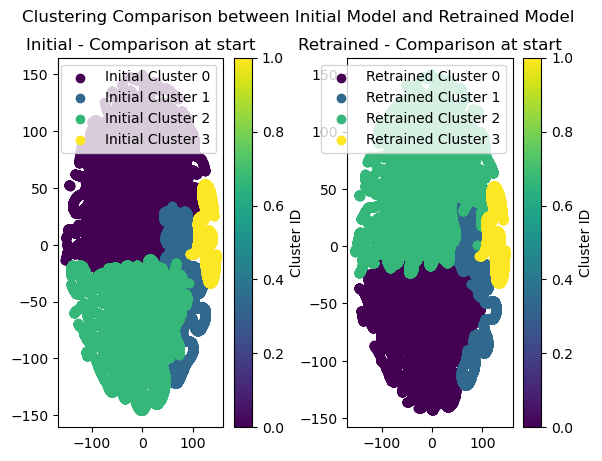

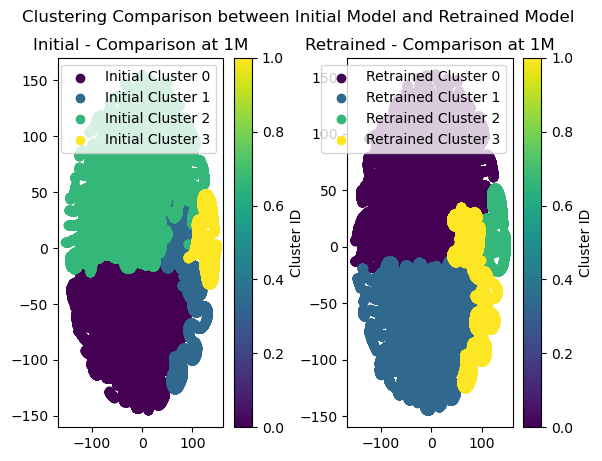

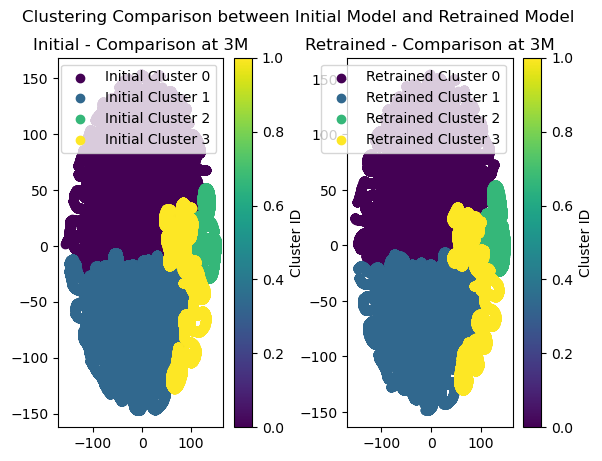

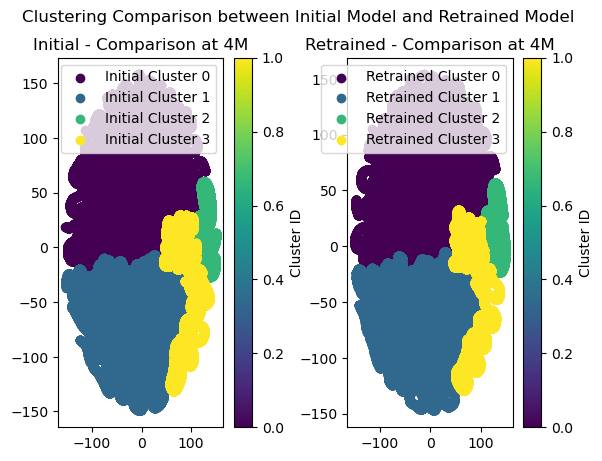

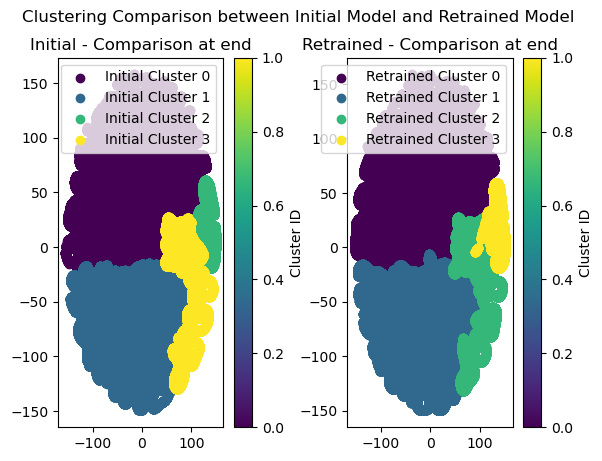

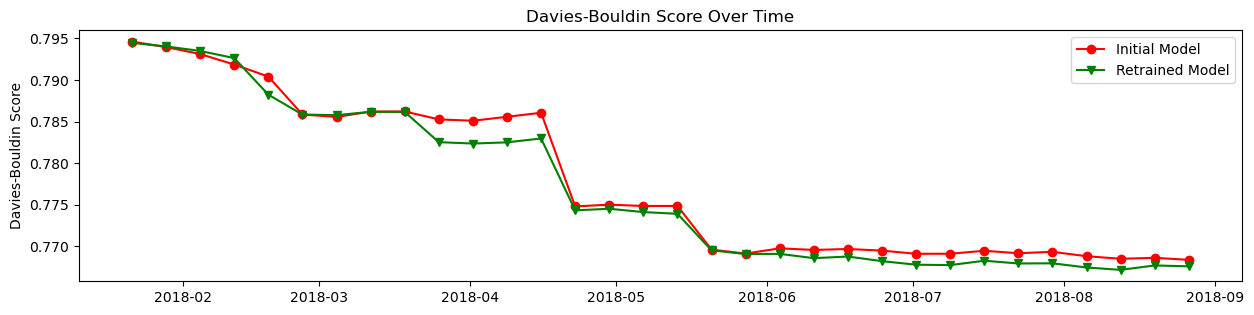

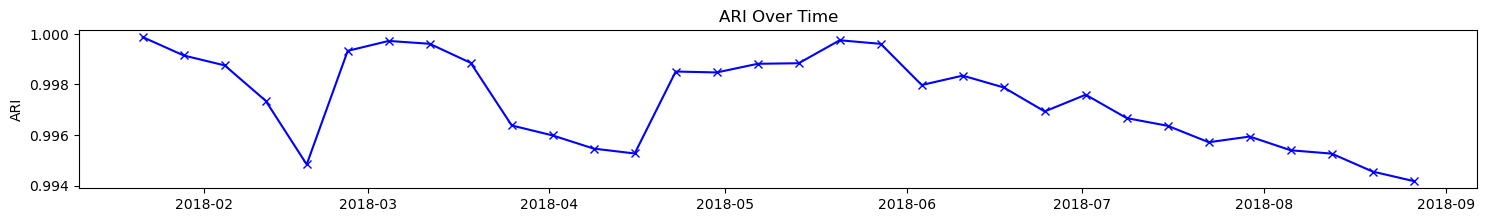

In [5]:
from datetime import timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import davies_bouldin_score, adjusted_rand_score
from sklearn.base import clone
from IPython.display import display

print("PARTIE 4 : ------------------------------ SIMULATION")

# Copy data for simulation
simulation_data = final_data.copy()

# Logarithmic Transformation
class LogTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, add_one=False):
        self.add_one = add_one

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if self.add_one:
            X = X + 1
        return np.log(X)

def plot_tsne_comparison(data_initial, clusters_initial, data_retrained, clusters_retrained, title):
    """
    This function visually compares two sets of data and clusters using t-SNE for dimensionality reduction.

    Parameters:
    data_initial (ndarray): Initial data.
    clusters_initial (ndarray): Initial clusters.
    data_retrained (ndarray): Data after retraining.
    clusters_retrained (ndarray): Clusters after retraining.
    title (str): Title of the plot.

    Returns:
    None
    """
    # Apply t-SNE separately on the initial and retrained data
    tsne_initial = TSNE(n_components=2, random_state=42).fit_transform(data_initial)
    tsne_retrained = TSNE(n_components=2, random_state=42).fit_transform(data_retrained)

    # Function to plot clusters with legend
    def plot_clusters(tsne_data, clusters, subplot, label_prefix):
        plt.subplot(1, 2, subplot)
        unique_clusters = np.unique(clusters)
        colors = plt.cm.get_cmap('viridis', len(unique_clusters))
        for i, cluster_num in enumerate(unique_clusters):
            cluster_data = tsne_data[clusters == cluster_num]
            plt.scatter(cluster_data[:, 0], cluster_data[:, 1], color=colors(i), label=f"{label_prefix} Cluster {cluster_num}")
        plt.legend()
        plt.colorbar().set_label('Cluster ID')
        plt.title(f"{label_prefix} - {title}")

    # Plot the t-SNE embeddings for initial model
    plot_clusters(tsne_initial, clusters_initial, 1, "Initial")

    # Plot the t-SNE embeddings for retrained model
    plot_clusters(tsne_retrained, clusters_retrained, 2, "Retrained")
    plt.suptitle("Clustering Comparison between Initial Model and Retrained Model")

    # Adjust the space between subplots
    plt.subplots_adjust(wspace=0.4)

    plt.show()

def get_cluster_distribution(initial_clusters, current_clusters):
    """This function calculates the distribution of clusters by comparing initial and current clusters.
    It returns a dictionary showing how many points from each initial cluster are in each current cluster."""

    cluster_distribution = {}
    unique_initial_clusters = np.unique(initial_clusters)
    unique_current_clusters = np.unique(current_clusters)

    for init_cluster in unique_initial_clusters:
        cluster_distribution[init_cluster] = {}
        for curr_cluster in unique_current_clusters:
            cluster_distribution[init_cluster][curr_cluster] = np.sum((initial_clusters == init_cluster) & (current_clusters == curr_cluster))

    return cluster_distribution

# Recall the adjusted Pipeline used:
optimal_clusters = 4

# Definition of columns and features
num_cols = ['total_payment_value', 'total_products']
cat_cols = ['perfect_score', 'has_multiple_orders']
features = num_cols + cat_cols

num_pipeline = Pipeline([
    ('log_transformer', LogTransformer(add_one=True)),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ])

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('kmeans', KMeans(n_clusters=optimal_clusters, random_state=42))
])

# Separate initial data (50%) and new data (50%)
# Sort the DataFrame by order_purchase_timestamp
sorted_data = final_data.sort_values(by='order_purchase_timestamp')

# Remove duplicates based on customer_unique_id, keeping the first occurrence (the oldest timestamp)
unique_data = sorted_data.drop_duplicates(subset='customer_unique_id', keep='first')

# Reset the index of the resulting DataFrame
unique_data.reset_index(drop=True, inplace=True)

# Calculate the split point to separate data into 50% initial and 50% new
split_point = int(0.5 * len(unique_data))

# Separate data into initial_data and new_data
initial_data = unique_data[:split_point]
new_data = unique_data[split_point:]

# Train the initial model
initial_model = pipeline.fit(initial_data[features])
initial_model_preprocessor = Pipeline(pipeline.steps[0:2]).fit(initial_data[features])

# Store the initial predicted clusters during the first week for tracking
initial_clusters = initial_model.predict(initial_data[features])

# ----

# Transform the data using the preprocessing pipeline
X_transformed = preprocessor.fit_transform(initial_data[features])

# Fit KMeans on the transformed data
initial_model.named_steps['kmeans'].fit(X_transformed)

# Predict clusters
initial_data.loc[:, 'cluster'] = initial_model.named_steps['kmeans'].predict(X_transformed)

# Calculate the Davies-Bouldin score
db_score = davies_bouldin_score(X_transformed, initial_data['cluster'])
print(f"Davies-Bouldin Score: {db_score}")

tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_transformed)

plt.subplot(1, 2, 2)
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=initial_data['cluster'])

# Create a legend with unique cluster labels
labels = np.unique(initial_data['cluster'])
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=scatter.cmap(scatter.norm(label)), markersize=10) for label in labels]
label_strings = [f"Cluster {label} - initial_data" for label in labels]
plt.legend(handles, label_strings, title='Clusters')
plt.title("Clustering of Initial Data with Initial Model")
plt.xlabel('TSNE 1')
plt.ylabel('TSNE 2')
plt.colorbar()

plt.show()

# ----

# Lists to store results
ari_values = []
periods = []

# Determine indices corresponding to specific intervals

# Calculate the number of weeks between start date and end date
start_date = pd.to_datetime(new_data['order_purchase_timestamp'].min())
end_date = pd.to_datetime(new_data['order_purchase_timestamp'].max())
num_weeks = (end_date - start_date).days // 7

# Update intervals_indices to encompass all dates until the end of the dataset
intervals_indices = {
    'start': 0,
    '1M': 4,
    '3M': 12,
    '4M': 16,
    'end': num_weeks  # Adding the last week
}

# Convert 'order_purchase_timestamp' column to datetime
new_data['order_purchase_timestamp'] = pd.to_datetime(new_data['order_purchase_timestamp'])

# Initialize lists to store Davies-Bouldin scores
davies_bouldin_initial_values = []
davies_bouldin_retrained_values = []

# Loop over each retraining period
for i, period in enumerate(pd.date_range(start=new_data['order_purchase_timestamp'].min(), end=new_data['order_purchase_timestamp'].max(), freq='1W')):

    # Select new data for the week
    data_new_week = pd.concat([initial_data, new_data[new_data['order_purchase_timestamp'] <= period]])

    if data_new_week.shape[0] < optimal_clusters:
        continue

    # Predict clusters with the initial model (not retrained) on all data
    clusters_initial = initial_model.predict(data_new_week[features])

    # Retrain the model with all available data up to this week
    retrained_model = clone(pipeline).fit(data_new_week[features])

    # Predict clusters with the retrained model
    clusters_retrained = retrained_model.predict(data_new_week[features])

    # If it's the first iteration, store the initial clusters for future comparisons
    if i == 0:
        initial_clusters_week_1 = clusters_initial.copy()
        retrained_clusters_week_1 = clusters_retrained.copy()  # Store retrained clusters in the first week

    # Calculate ARI
    ari = adjusted_rand_score(clusters_initial, clusters_retrained)
    ari_values.append(ari)

    # Calculate Davies-Bouldin
    data_new_week_transformed = preprocessor.transform(data_new_week[features])

    # Compute Davies-Bouldin score on the transformed data
    db_initial_transformed = davies_bouldin_score(data_new_week_transformed, clusters_initial)
    db_retrained_transformed = davies_bouldin_score(data_new_week_transformed, clusters_retrained)

    # Add these values to lists for later tracking
    davies_bouldin_initial_values.append(db_initial_transformed)
    davies_bouldin_retrained_values.append(db_retrained_transformed)

    # Check if the index corresponds to one of the defined intervals and plot t-SNE if needed
    for interval, index in intervals_indices.items():
        if i == index:

            # Transform features using the pipeline of the initial model
            data_transformed_initial = initial_model_preprocessor.transform(data_new_week[features])

            # Transform features using the pipeline of the retrained model
            retrained_model = Pipeline(pipeline.steps[0:2])
            data_transformed_retrained = retrained_model.fit_transform(data_new_week[features])

            # Call the plot_tsne_comparison function with transformed data for each model
            plot_tsne_comparison(data_transformed_initial, clusters_initial, data_transformed_retrained, clusters_retrained, f'Comparison at {interval}')

    # Add the period to the list of periods
    periods.append(period)

# Plot the results (Davies-Bouldin score and ARI)
plt.figure(figsize=(15, 15))

# Subplot for Davies-Bouldin in a larger size
plt.subplot(4, 1, 3)  # You can change the grid if needed
plt.plot(periods, davies_bouldin_initial_values, 'ro-', label='Initial Model')
plt.plot(periods, davies_bouldin_retrained_values, 'gv-', label='Retrained Model')
plt.title('Davies-Bouldin Score Over Time')
plt.ylabel('Davies-Bouldin Score')
plt.legend()

plt.figure(figsize=(15, 8))
plt.subplot(4, 1, 1)
plt.plot(periods, ari_values, 'bx-')
plt.title('ARI Over Time')
plt.ylabel('ARI')

plt.tight_layout()
plt.show()

In [6]:
# Affiche la date de début des données
start_date_all_data = final_data['order_purchase_timestamp'].min()
print(f"La date de début de toutes les données est : {start_date_all_data}")
# Afficher la date où débute l'ajout des nouvelles données
start_date_new_data = new_data['order_purchase_timestamp'].min()
print(f"L'ajout des nouvelles données commence à partir de la date : {start_date_new_data}")
# Affiche la date la plus récente dans l'ensemble de données
latest_date = new_data['order_purchase_timestamp'].max()
print(f"La date la plus récente dans l'ensemble de données est : {latest_date}")

La date de début de toutes les données est : 2016-09-04 21:15:19
L'ajout des nouvelles données commence à partir de la date : 2018-01-19 13:22:28
La date la plus récente dans l'ensemble de données est : 2018-08-29 15:00:37


# résultat précédent avec une séparation à 70%, 30% entre le dataset initial et le dataset avec les nouvelles entrées

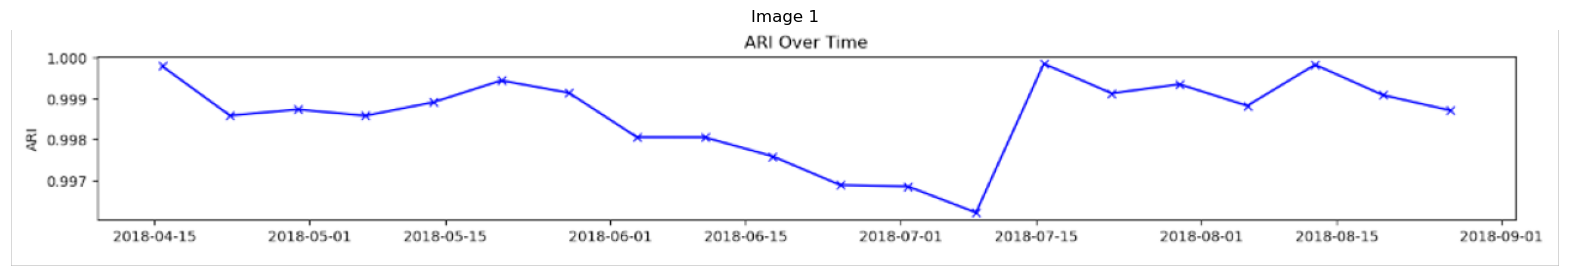

In [17]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Path to the first image
image_path1 = "0703splitari.png"

# Read the first image
img1 = mpimg.imread(image_path1)

# Create a figure
plt.figure(figsize=(20, 10))

# Display the first image
plt.imshow(img1)
plt.title("Image 1")
plt.axis('off')

# Show the figure
plt.show()


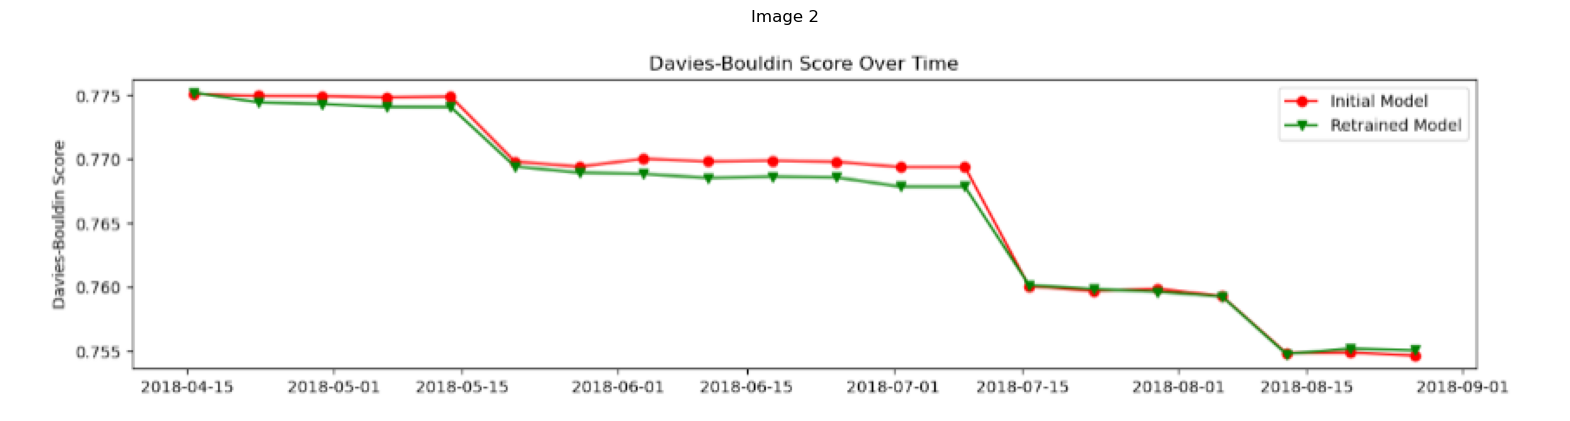

In [16]:
# Path to the second image
image_path2 = "0703splitdavies.png"

# Read the second image
img2 = mpimg.imread(image_path2)

# Create another figure
plt.figure(figsize=(20, 10))

# Display the second image
plt.imshow(img2)
plt.title("Image 2")
plt.axis('off')

# Show the figure
plt.show()


Performance Cohérente : Si les scores ARI (Indice de Rand Ajusté) et Davies-Bouldin sont cohérents à travers différentes divisions de données, cela indique généralement que le modèle de clustering est stable et robuste face aux variations dans la distribution des données.

Effet du Réentraînement : Si les scores restent cohérents avant et après le réentraînement, c'est un indicateur fort que le modèle de clustering généralise bien, et un réentraînement peut ne pas être nécessaire aussi fréquemment.